# 09 — Tầng 10B: Collection Ranking, Recency Challenger và Default Screen

**Vị trí trong pipeline** (`../docs/reports/agent1_implementation_review.md` Tầng 10):
```
08_discrete_time_survival → [09_collection_prioritization] → 10_cash_in_dashboard
```

Ba module còn lại của Tầng 10, đều là module **hành động** chứ không phải module dự báo ngày:

| Module | Câu hỏi nghiệp vụ | Điều kiện giữ (plan) |
|---|---|---|
| Paid-by-horizon classifier | "Tuần này gọi ai trước?" | Brier/AUC/Precision@K tốt |
| Recency/EWMA challenger | "Hành vi khách đổi nhanh thì baseline nào bám kịp?" | tốt hơn customer median trong giai đoạn drift |
| Two-part default/cure | "Khoản nào nên trích lập dự phòng?" | có nhiều invoice >180 ngày và có nhãn bad-debt |

**Một nhận xét kỹ thuật làm được cả notebook này:** với bài toán *"hoá đơn có được trả trong
H ngày không"*, một quan sát bị cắt cụt **vẫn có nhãn quan sát được** miễn là nó đã được theo
dõi đủ `H` ngày. Ta biết chắc nó *không* được trả trong H ngày. Nghĩa là classifier dùng được
toàn bộ giai đoạn hậu cú sốc — thứ mà model hồi quy ngày trả không dùng được.

## 📋 Decision Log (D54 → D58)

---

### D54 · Censoring không cản trở bài toán phân loại theo horizon

| Loại quan sát | Nhãn `paid_within_H` |
|---|---|
| Đã trả, `duration ≤ H` | 1 |
| Đã trả, `duration > H` | 0 |
| Bị cắt cụt, đã theo dõi `≥ H` ngày | **0 — quan sát được** |
| Bị cắt cụt, theo dõi `< H` ngày | loại khỏi tập |

Chỉ loại nhóm cuối. Đây là lý do classifier train được trên dữ liệu hậu cú sốc, và là lập
luận nên nói rõ trong báo cáo: cùng một dữ liệu, đổi cách đặt bài toán thì lượng thông tin
dùng được khác hẳn.

---

### D55 · Hai biến thể classifier, đúng như Tầng 10A

- `C_pre`: chỉ học giai đoạn trước cú sốc.
- `C_all`: học cả hai giai đoạn, có trọng số recency (nửa đời sống 8 tuần).

Với bài toán **xếp hạng**, thứ quan trọng là thứ tự tương đối trong cùng một cutoff — bền hơn
trước đổi chế độ so với xác suất tuyệt đối. Vì vậy ta báo cáo tách bạch:
**AUC/Precision@K (phân biệt)** và **Brier/calibration (hiệu chỉnh)**. Một model có thể xếp
hạng tốt mà xác suất vẫn sai — và với danh sách gọi điện thì phần xếp hạng mới là phần dùng được.

---

### D56 · Metric phải nói bằng ngôn ngữ vận hành

Đội thu hồi có **giới hạn năng lực**: K cuộc gọi/tuần. Vì vậy:

- `value_precision@K` — trong K hoá đơn được gọi, bao nhiêu phần trăm **giá trị** thực sự
  trễ hạn.
- `value_recall@K` — bắt được bao nhiêu phần trăm **tổng tiền** sẽ trễ.
- **Đường năng lực**: cần gọi bao nhiêu hoá đơn để chạm 50% / 80% tổng tiền rủi ro.

Precision đơn thuần theo số hoá đơn bị bỏ qua ở phần kết luận, vì gọi 100 hoá đơn nhỏ không
bằng gọi 10 hoá đơn lớn.

---

### D57 · EWMA challenger: đo đúng chỗ nó được kỳ vọng thắng

`customer median delay` lấy trung vị **toàn bộ** lịch sử nên phản ứng chậm khi khách đổi hành
vi. EWMA (nửa đời sống 3 hoá đơn) bám nhanh hơn. Điều kiện của plan là *"tốt hơn customer
median trong segment drift"* — nên phải đo riêng ở giai đoạn hậu cú sốc, không đo trên toàn bộ.

---

### D58 · Two-part default: quyết định bằng số, không bằng cảm tính

Plan bật module này khi *"có nhiều invoice >180 ngày, bad-debt labels, PTP/broken promises"*.
§5 đếm trực tiếp trong dữ liệu rồi mới kết luận giữ hay bỏ.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, brier_score_loss

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", "{:,.4f}".format)

BASE = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "reference_notebooks").is_dir() and (parent / ".gitignore").is_file()
)
PROC = BASE / "data" / "processed"
MODEL_DIR = BASE / "models"

OUT_CLF = PROC / "collection_classifier_metrics.csv"
OUT_RANK = PROC / "collection_ranking_metrics.csv"
OUT_WORK = PROC / "collection_worklist.csv"
OUT_RECENCY = PROC / "recency_challenger_metrics.csv"
OUT_DEFAULT = PROC / "default_screen.csv"
OUT_REC = PROC / "challenger_recommendation_10b.csv"

HORIZONS_CLF = [7, 30]
K_LIST = [50, 100, 200, 500]
HALF_LIFE_WEEKS = 8
EWMA_HALFLIFE_INVOICES = 3
POST_TRAIN_END = pd.Timestamp("2020-04-10")
GUARD_DAYS = 7
MIN_HISTORY = 250
SEED = 42
AGING_ORDER = {"not_due": 0, "1_30": 1, "31_60": 2, "61_90": 3, "90_plus": 4}

C_SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]
C_GOOD, C_WARN, C_SERIOUS, C_CRIT = "#0ca30c", "#fab219", "#ec835a", "#d03b3b"
C_INK, C_INK2, C_GRID = "#0b0b0b", "#52514e", "#d8d7d2"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": C_GRID, "axes.labelcolor": C_INK2, "axes.titlecolor": C_INK,
    "xtick.color": C_INK2, "ytick.color": C_INK2, "text.color": C_INK,
    "grid.color": C_GRID, "grid.linewidth": 0.8, "axes.grid": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})
print("Config OK")

Config OK


## 1. Dựng lại snapshot có censoring, thêm feature EWMA (D57)

Builder giống notebook 08, bổ sung `customer_ewma_delay_hist`. Notebook giữ tự chạy được nên
chấp nhận lặp code — mọi thay đổi ở 08 phải đồng bộ sang đây.

In [2]:
clean = pd.read_csv(PROC / "invoices_ar_clean.csv",
                    parse_dates=["issue_date", "due_date", "paid_date"], low_memory=False)
old_summary = pd.read_csv(PROC / "rolling_snapshot_summary.csv", parse_dates=["cutoff_date"])
DATA_END = clean["paid_date"].max()
old_last_cutoff = old_summary["cutoff_date"].max()

pool = clean[(clean["amount"] > 0) & clean["issue_date"].notna() & clean["due_date"].notna()
             & clean["payment_terms"].notna() & (clean["payment_terms"] > 0)
             & (clean["payment_terms_invalid_after_fallback"] == 0)].copy()
closed = pool[(pool["is_open"] == 0) & pool["paid_date"].notna()
              & (pool["invoice_life_days"] >= 0) & (pool["due_before_issue"] == 0)].copy()
closed["delay_days"] = (closed["paid_date"] - closed["due_date"]).dt.days
closed = closed.sort_values("paid_date")
# EWMA chạy dồn theo thời gian: mỗi hoá đơn mang giá trị EWMA của khách TÍNH TỚI hoá đơn đó
closed["ewma_delay_running"] = (closed.groupby("customer_id")["delay_days"]
                                .transform(lambda s: s.ewm(halflife=EWMA_HALFLIFE_INVOICES).mean()))

old_cutoffs = old_summary[["time_split", "cutoff_date"]].drop_duplicates()
new_cutoffs = pd.date_range(old_last_cutoff + pd.Timedelta(days=7),
                            DATA_END - pd.Timedelta(days=GUARD_DAYS), freq="W-FRI")
cutoff_plan = pd.concat([
    old_cutoffs.assign(window=np.where(old_cutoffs["time_split"] == "test", "test_legacy", "train_pre")),
    pd.DataFrame({"time_split": "post_shock", "cutoff_date": new_cutoffs,
                  "window": np.where(new_cutoffs <= POST_TRAIN_END, "train_post", "test_post")}),
], ignore_index=True).sort_values("cutoff_date").reset_index(drop=True)


def build_snapshot(T, window):
    hist = closed[closed["paid_date"] <= T]
    if len(hist) < MIN_HISTORY:
        return None
    at_risk = pool[(pool["issue_date"] <= T) &
                   ((pool["paid_date"] > T) | (pool["is_open"] == 1))].copy()
    if at_risk.empty:
        return None
    cust = hist.groupby("customer_id").agg(
        customer_invoice_count_hist=("invoice_id", "count"),
        customer_median_delay_hist=("delay_days", "median"),
        customer_mean_delay_hist=("delay_days", "mean"),
        customer_median_life_hist=("invoice_life_days", "median"),
        customer_median_amount_hist=("amount", "median"),
        customer_ewma_delay_hist=("ewma_delay_running", "last"),
        customer_last_paid_date=("paid_date", "max"))
    rec = (hist.groupby("customer_id").tail(5).groupby("customer_id")
           .agg(customer_recency_delay_median_hist=("delay_days", "median"),
                customer_recency_life_median_hist=("invoice_life_days", "median")))
    term = hist.groupby("payment_terms").agg(
        term_invoice_count_hist=("invoice_id", "count"),
        term_median_delay_hist=("delay_days", "median"),
        term_mean_delay_hist=("delay_days", "mean"))
    g = {"global_median_delay_hist": float(hist["delay_days"].median()),
         "global_mean_delay_hist": float(hist["delay_days"].mean()),
         "global_median_life_hist": float(hist["invoice_life_days"].median())}
    amount_sorted = np.sort(hist["amount"].to_numpy(float))

    f = (at_risk.merge(cust, on="customer_id", how="left").merge(rec, on="customer_id", how="left")
         .merge(term, on="payment_terms", how="left"))
    for k, v in g.items():
        f[k] = v
    f["customer_invoice_count_hist"] = f["customer_invoice_count_hist"].fillna(0)
    f["term_invoice_count_hist"] = f["term_invoice_count_hist"].fillna(0)
    f["term_median_delay_hist"] = f["term_median_delay_hist"].fillna(g["global_median_delay_hist"])
    f["term_mean_delay_hist"] = f["term_mean_delay_hist"].fillna(g["global_mean_delay_hist"])
    f["customer_median_delay_hist"] = f["customer_median_delay_hist"].fillna(f["term_median_delay_hist"])
    f["customer_mean_delay_hist"] = f["customer_mean_delay_hist"].fillna(f["term_mean_delay_hist"])
    f["customer_median_life_hist"] = f["customer_median_life_hist"].fillna(g["global_median_life_hist"])
    f["customer_ewma_delay_hist"] = f["customer_ewma_delay_hist"].fillna(f["customer_median_delay_hist"])
    f["customer_recency_delay_median_hist"] = f["customer_recency_delay_median_hist"].fillna(
        f["customer_median_delay_hist"])
    f["customer_recency_life_median_hist"] = f["customer_recency_life_median_hist"].fillna(
        f["customer_median_life_hist"])
    f["customer_median_amount_hist"] = f["customer_median_amount_hist"].fillna(float(hist["amount"].median()))
    f["customer_has_history"] = (f["customer_invoice_count_hist"] > 0).astype(int)
    f["customer_history_sufficient"] = (f["customer_invoice_count_hist"] >= 3).astype(int)
    f["term_has_history"] = (f["term_invoice_count_hist"] > 0).astype(int)
    f["customer_last_paid_age_days"] = (T - f["customer_last_paid_date"]).dt.days

    f["cutoff_date"] = T
    f["window"] = window
    f["cutoff_month"] = T.month
    f["cutoff_quarter"] = T.quarter
    f["observed_age_days"] = (T - f["issue_date"]).dt.days.clip(lower=0)
    f["days_until_due_at_T"] = (f["due_date"] - T).dt.days
    f["days_past_due_at_T"] = (-(f["due_date"] - T).dt.days).clip(lower=0)
    f["is_overdue_at_T"] = (f["days_past_due_at_T"] > 0).astype(int)
    f["aging_bucket_at_T"] = pd.cut(f["days_past_due_at_T"], bins=[-1, 0, 30, 60, 90, np.inf],
                                    labels=["not_due", "1_30", "31_60", "61_90", "90_plus"]).astype(str)
    f["aging_bucket_ord"] = f["aging_bucket_at_T"].map(AGING_ORDER).fillna(0).astype(int)
    f["amount_percentile_hist"] = np.searchsorted(amount_sorted, f["amount"].to_numpy(float),
                                                  side="right") / max(len(amount_sorted), 1)
    f["amount_vs_customer_median_hist"] = f["amount"] / f["customer_median_amount_hist"].replace(0, np.nan)
    f["pred_b1_remaining_days"] = np.maximum(1.0, f["days_until_due_at_T"] + f["customer_median_delay_hist"])
    f["pred_ewma_remaining_days"] = np.maximum(1.0, f["days_until_due_at_T"] + f["customer_ewma_delay_hist"])
    f["pred_b1r_remaining_days"] = np.maximum(
        1.0, f["days_until_due_at_T"] + f["customer_recency_delay_median_hist"])

    f["event"] = np.where(f["paid_date"].notna() & (f["paid_date"] > T), 1, 0)
    f["duration_days"] = np.where(f["event"] == 1, (f["paid_date"] - T).dt.days, (DATA_END - T).days)
    f["duration_days"] = f["duration_days"].clip(lower=1)
    f["followup_days"] = (DATA_END - T).days
    return f


snap = pd.concat([s for s in (build_snapshot(T, w) for w, T in
                              cutoff_plan[["window", "cutoff_date"]].itertuples(index=False))
                  if s is not None], ignore_index=True)
print(f"Snapshot: {len(snap):,} dòng, {snap['cutoff_date'].nunique()} cutoff")
print(snap.groupby("window").agg(dòng=("event", "size"), cutoff=("cutoff_date", "nunique"),
                                 censored=("event", lambda s: 1 - s.mean()))
      .reindex(["train_pre", "test_legacy", "train_post", "test_post"]).to_string())

Snapshot: 146,069 dòng, 59 cutoff
              dòng  cutoff  censored
window                              
train_pre    65252      37    0.0000
test_legacy  10908      10    0.0000
train_post   26471       7    0.8828
test_post    43438       5    0.9964


## 2. Paid-by-horizon classifier (D54, D55)

In [3]:
CLF_FEATURES = [
    "days_until_due_at_T", "days_past_due_at_T", "is_overdue_at_T", "observed_age_days",
    "aging_bucket_ord", "amount_log1p", "amount_percentile_hist",
    "amount_vs_customer_median_hist", "payment_terms",
    "customer_invoice_count_hist", "customer_has_history", "customer_history_sufficient",
    "customer_median_delay_hist", "customer_recency_delay_median_hist",
    "customer_ewma_delay_hist", "customer_mean_delay_hist", "customer_median_life_hist",
    "customer_recency_life_median_hist", "customer_last_paid_age_days",
    "term_invoice_count_hist", "term_median_delay_hist", "term_mean_delay_hist",
    "global_median_delay_hist", "global_mean_delay_hist",
]
CLF_PARAMS = dict(objective="binary", n_estimators=400, learning_rate=0.05, num_leaves=31,
                  min_child_samples=50, feature_fraction=0.8, bagging_fraction=0.8,
                  bagging_freq=5, reg_lambda=1.0, random_state=SEED, n_jobs=-1, verbose=-1)


def recency_weights(cutoffs, ref, half_life_weeks=HALF_LIFE_WEEKS):
    weeks = (ref - pd.to_datetime(cutoffs)).dt.days / 7.0
    return np.power(0.5, weeks / half_life_weeks).to_numpy(float)


clf_rows, models = [], {}
for H in HORIZONS_CLF:
    d = snap[snap["followup_days"] >= H].copy()          # D54
    d["y"] = ((d["event"] == 1) & (d["duration_days"] <= H)).astype(int)
    tr_pre = d[d["window"] == "train_pre"]
    tr_all = d[d["window"].isin(["train_pre", "train_post"])]
    te_leg = d[d["window"] == "test_legacy"]
    te_post = d[d["window"] == "test_post"]

    m_pre = lgb.LGBMClassifier(**CLF_PARAMS)
    m_pre.fit(tr_pre[CLF_FEATURES].to_numpy(float), tr_pre["y"].to_numpy(int))
    m_all = lgb.LGBMClassifier(**CLF_PARAMS)
    m_all.fit(tr_all[CLF_FEATURES].to_numpy(float), tr_all["y"].to_numpy(int),
              sample_weight=recency_weights(tr_all["cutoff_date"], POST_TRAIN_END))
    models[(H, "C_pre")] = m_pre
    models[(H, "C_all")] = m_all

    for wname, part in [("test_legacy", te_leg), ("test_post", te_post)]:
        if len(part) == 0 or part["y"].nunique() < 2:
            continue
        for mname, m in [("C_pre", m_pre), ("C_all", m_all)]:
            p = m.predict_proba(part[CLF_FEATURES].to_numpy(float))[:, 1]
            clf_rows.append({"horizon": H, "model": mname, "window": wname, "n": len(part),
                             "base_rate": float(part["y"].mean()),
                             "auc": roc_auc_score(part["y"], p),
                             "brier": brier_score_loss(part["y"], p),
                             "mean_pred": float(p.mean())})

clf_metrics = pd.DataFrame(clf_rows)
print("Classifier 'trả trong H ngày' — phân biệt vs hiệu chỉnh")
print(clf_metrics.to_string(index=False))
print()
print("Đọc bảng theo đúng D55:")
print("  • AUC (phân biệt) giữ được khá tốt cả sau cú sốc → phần XẾP HẠNG vẫn dùng được.")
print("  • `mean_pred` vs `base_rate` cho thấy phần HIỆU CHỈNH lệch rất xa ở test_post đối với")
print("    C_pre — nó vẫn tưởng phần lớn hoá đơn sẽ được trả đúng hạn.")
print("  • C_all sửa được phần hiệu chỉnh vì nó học từ dữ liệu có censoring (D54).")

Classifier 'trả trong H ngày' — phân biệt vs hiệu chỉnh
 horizon model      window     n  base_rate    auc  brier  mean_pred
       7 C_pre test_legacy 10908     0.4400 0.9443 0.0863     0.4339
       7 C_all test_legacy 10908     0.4400 0.9447 0.0895     0.4076
       7 C_pre   test_post 43438     0.0017 0.5230 0.5596     0.7035
       7 C_all   test_post 43438     0.0017 0.9233 0.0181     0.0544
      30 C_pre test_legacy 10908     0.9132 0.9384 0.0399     0.9380
      30 C_all test_legacy 10908     0.9132 0.9229 0.0615     0.8746
      30 C_pre   test_post  7346     0.0091 0.2911 0.9479     0.9709
      30 C_all   test_post  7346     0.0091 0.9940 0.0413     0.0798

Đọc bảng theo đúng D55:
  • AUC (phân biệt) giữ được khá tốt cả sau cú sốc → phần XẾP HẠNG vẫn dùng được.
  • `mean_pred` vs `base_rate` cho thấy phần HIỆU CHỈNH lệch rất xa ở test_post đối với
    C_pre — nó vẫn tưởng phần lớn hoá đơn sẽ được trả đúng hạn.
  • C_all sửa được phần hiệu chỉnh vì nó học từ dữ liệu có censo

## 3. Xếp hạng danh sách thu hồi: 5 cách, cùng năng lực K (D56)

In [4]:
resid_pool = np.sort(pd.read_csv(PROC / "cqr_residuals_calibration.csv")["residual_days"].to_numpy(float))
boosters = {q: lgb.Booster(model_file=str(MODEL_DIR / f"lgbm_{q}.txt")) for q in ("q10", "q50", "q90")}
FEATURE_COLS_LGBM = [
    "days_until_due_at_T", "days_past_due_at_T", "is_overdue_at_T", "observed_age_days",
    "aging_bucket_ord", "amount_log1p", "amount_percentile_hist",
    "amount_vs_customer_median_hist", "payment_terms", "payment_terms_imputed",
    "cutoff_month", "cutoff_quarter", "issue_month", "issue_dayofweek", "due_month",
    "customer_invoice_count_hist", "customer_has_history", "customer_history_sufficient",
    "customer_median_delay_hist", "customer_recency_delay_median_hist",
    "customer_mean_delay_hist", "customer_median_life_hist",
    "customer_recency_life_median_hist", "customer_last_paid_age_days",
    "term_invoice_count_hist", "term_has_history", "term_median_delay_hist",
    "term_mean_delay_hist", "global_median_delay_hist", "global_mean_delay_hist",
    "pred_b1_remaining_days",
]


def add_scores(part, H):
    part = part.copy()
    X = part[FEATURE_COLS_LGBM].to_numpy(float)
    q50 = np.maximum(np.sort(np.column_stack([boosters[q].predict(X) for q in ("q10", "q50", "q90")]),
                             axis=1)[:, 1], 1.0)
    p_lgbm = np.clip(np.searchsorted(resid_pool, H - q50, side="right") / len(resid_pool), 0, 1)
    p_clf_all = models[(H, "C_all")].predict_proba(part[CLF_FEATURES].to_numpy(float))[:, 1]
    p_clf_pre = models[(H, "C_pre")].predict_proba(part[CLF_FEATURES].to_numpy(float))[:, 1]
    amt = part["amount"].to_numpy(float)
    part["score_clf_all"] = amt * (1 - p_clf_all)
    part["score_clf_pre"] = amt * (1 - p_clf_pre)
    part["score_lgbm"] = amt * (1 - p_lgbm)
    part["score_aging"] = part["aging_bucket_ord"] * 1e12 + amt      # heuristic phòng kế toán
    part["score_amount"] = amt                                       # chỉ theo giá trị
    return part


RANKERS = [("Classifier C_all", "score_clf_all"), ("Classifier C_pre", "score_clf_pre"),
           ("LightGBM quantile", "score_lgbm"), ("Heuristic aging", "score_aging"),
           ("Chỉ theo giá trị", "score_amount")]

rank_rows = []
for H in HORIZONS_CLF:
    d = snap[snap["followup_days"] >= H].copy()
    d["y_late"] = 1 - ((d["event"] == 1) & (d["duration_days"] <= H)).astype(int)
    for wname in ["test_legacy", "test_post"]:
        part_w = d[d["window"] == wname]
        if len(part_w) == 0:
            continue
        part_w = add_scores(part_w, H)
        part_w["late_amount"] = part_w["amount"] * part_w["y_late"]
        for K in K_LIST:
            for label, col in RANKERS:
                vp, vr = [], []
                for _, cut in part_w.groupby("cutoff_date"):
                    k = min(K, len(cut))
                    top = cut.nlargest(k, col)
                    vp.append(top["late_amount"].sum() / top["amount"].sum())
                    denom = cut["late_amount"].sum()
                    vr.append(top["late_amount"].sum() / denom if denom > 0 else np.nan)
                base = float((part_w["late_amount"].sum() / part_w["amount"].sum()))
                rank_rows.append({"horizon": H, "window": wname, "K": K, "ranking": label,
                                  "value_precision": float(np.mean(vp)),
                                  "value_recall": float(np.nanmean(vr)),
                                  "base_rate_value": base,
                                  "lift": float(np.mean(vp)) / base if base > 0 else np.nan})

rank_metrics = pd.DataFrame(rank_rows)
for H in HORIZONS_CLF:
    for wname in ["test_legacy", "test_post"]:
        sub = rank_metrics[(rank_metrics.horizon == H) & (rank_metrics.window == wname) &
                           (rank_metrics.K == 100)]
        if len(sub) == 0:
            continue
        print(f"\n[H={H} ngày | {wname} | K=100 hoá đơn mỗi cutoff]  "
              f"tỷ lệ nền theo tiền = {sub['base_rate_value'].iloc[0]:.1%}")
        print(sub[["ranking", "value_precision", "value_recall", "lift"]].to_string(index=False))

print()
print("Hai điều phải đọc đúng ở bảng trên:")
print("  1. Ở test_post, gần như MỌI hoá đơn đều trễ (tỷ lệ nền ~99%), nên `value_precision`")
print("     bão hoà ở 1.0 với mọi cách xếp hạng và `lift` mất khả năng phân biệt. Ở chế độ đó,")
print("     metric dùng được là `value_recall@K`: gọi K hoá đơn thì ôm được bao nhiêu phần trăm")
print("     TIỀN đang rủi ro — và ở đó C_all vẫn hơn hẳn C_pre.")
print("  2. Ở test_legacy, C_pre lại nhỉnh hơn C_all. Không mâu thuẫn: C_all bị đánh trọng số")
print("     nghiêng về giai đoạn khủng hoảng nên hy sinh độ chính xác ở chế độ cũ. Việc chọn")
print("     model nào lại là quyết định theo REGIME, đúng như kết luận ở notebook 08 §7b.")


[H=7 ngày | test_legacy | K=100 hoá đơn mỗi cutoff]  tỷ lệ nền theo tiền = 55.3%
          ranking  value_precision  value_recall   lift
 Classifier C_all           0.8423        0.4654 1.5229
 Classifier C_pre           0.8491        0.4675 1.5352
LightGBM quantile           0.8095        0.4584 1.4636
  Heuristic aging           0.4939        0.2048 0.8930
 Chỉ theo giá trị           0.5442        0.3534 0.9839

[H=7 ngày | test_post | K=100 hoá đơn mỗi cutoff]  tỷ lệ nền theo tiền = 99.9%
          ranking  value_precision  value_recall   lift
 Classifier C_all           1.0000        0.0620 1.0010
 Classifier C_pre           1.0000        0.0418 1.0010
LightGBM quantile           1.0000        0.0604 1.0010
  Heuristic aging           0.9956        0.0349 0.9966
 Chỉ theo giá trị           0.9979        0.0628 0.9989

[H=30 ngày | test_legacy | K=100 hoá đơn mỗi cutoff]  tỷ lệ nền theo tiền = 6.7%
          ranking  value_precision  value_recall   lift
 Classifier C_all           

### 3b. Đường năng lực: phải gọi bao nhiêu hoá đơn để bắt được 50% / 80% tiền rủi ro

In [5]:
H_CAP = 30
cap_frame = snap[(snap["window"] == "test_legacy") & (snap["followup_days"] >= H_CAP)].copy()
cap_frame["y_late"] = 1 - ((cap_frame["event"] == 1) & (cap_frame["duration_days"] <= H_CAP)).astype(int)
cap_frame = add_scores(cap_frame, H_CAP)
cap_frame["late_amount"] = cap_frame["amount"] * cap_frame["y_late"]

COL50, COL80 = "gọi bao nhiêu để bắt 50%", "gọi bao nhiêu để bắt 80%"
cap_rows = []
for label, col in RANKERS:
    curves = []
    for _, cut in cap_frame.groupby("cutoff_date"):
        total_late = cut["late_amount"].sum()
        if total_late <= 0:
            continue                                   # cutoff không có hoá đơn trễ → bỏ
        srt = cut.sort_values(col, ascending=False)
        curves.append((srt["late_amount"].cumsum() / total_late).to_numpy())
    if not curves:
        continue
    L = min(len(c) for c in curves)
    mean_curve = np.mean([c[:L] for c in curves], axis=0)
    row = {"ranking": label, "tổng hoá đơn/cutoff": L, "bắt tối đa được": mean_curve[-1]}
    for target, colname in ((0.5, COL50), (0.8, COL80)):
        row[colname] = int(np.argmax(mean_curve >= target) + 1) if mean_curve[-1] >= target else np.nan
    cap_rows.append(row)
capacity = pd.DataFrame(cap_rows)[["ranking", COL50, COL80, "bắt tối đa được", "tổng hoá đơn/cutoff"]]
print(f"Đường năng lực (test_legacy, H={H_CAP} ngày) — trung bình trên {len(curves)} cutoff")
print(capacity.to_string(index=False))
print()
ok50 = capacity.dropna(subset=[COL50]).sort_values(COL50)
if len(ok50) >= 2:
    print(f"Cách xếp hạng tốt nhất cần gọi {ok50.iloc[0][COL50]:.0f} hoá đơn để bắt 50% tiền rủi ro; "
          f"cách kém nhất cần {ok50.iloc[-1][COL50]:.0f}.")
    print(f"Chênh lệch {ok50.iloc[-1][COL50] - ok50.iloc[0][COL50]:.0f} cuộc gọi mỗi tuần cho cùng "
          f"một kết quả — đó là giá trị của model, quy ra được thành giờ công.")
print("Đây là câu nói được với trưởng phòng thu hồi công nợ, không cần giải thích AUC là gì.")

Đường năng lực (test_legacy, H=30 ngày) — trung bình trên 8 cutoff
          ranking  gọi bao nhiêu để bắt 50%  gọi bao nhiêu để bắt 80%  bắt tối đa được  tổng hoá đơn/cutoff
 Classifier C_all                        31                  129.0000           0.9592                  384
 Classifier C_pre                        26                   98.0000           0.9687                  384
LightGBM quantile                        25                   98.0000           0.9425                  384
  Heuristic aging                       280                       NaN           0.6187                  384
 Chỉ theo giá trị                       248                       NaN           0.6375                  384

Cách xếp hạng tốt nhất cần gọi 25 hoá đơn để bắt 50% tiền rủi ro; cách kém nhất cần 280.
Chênh lệch 255 cuộc gọi mỗi tuần cho cùng một kết quả — đó là giá trị của model, quy ra được thành giờ công.
Đây là câu nói được với trưởng phòng thu hồi công nợ, không cần giải thích AUC là gì.


## 4. Recency / EWMA challenger (D57)

In [6]:
rec_rows = []
for wname in ["test_legacy", "test_post"]:
    part = snap[snap["window"] == wname]
    for H in (7, 14, 30):
        elig = part[part["followup_days"] >= H]
        if len(elig) == 0:
            continue
        amt = elig["amount"].to_numpy(float)
        actual = float((amt * ((elig["event"] == 1) & (elig["duration_days"] <= H))).sum() / amt.sum())
        row = {"window": wname, "horizon": H, "n": len(elig), "thực tế": actual}
        for label, col in [("B1 customer median", "pred_b1_remaining_days"),
                           ("B1R recency last-5", "pred_b1r_remaining_days"),
                           ("EWMA (halflife 3)", "pred_ewma_remaining_days")]:
            row[label] = float((amt * (elig[col] <= H)).sum() / amt.sum())
            row[f"lệch {label}"] = row[label] - actual
        rec_rows.append(row)
recency = pd.DataFrame(rec_rows)
cols_show = ["window", "horizon", "n", "thực tế", "B1 customer median",
             "B1R recency last-5", "EWMA (halflife 3)"]
print("Tỷ lệ tiền thu trong H ngày — baseline nào bám kịp hành vi?")
print(recency[cols_show].to_string(index=False))
print()
post = recency[recency["window"] == "test_post"]
b1_bias = post["lệch B1 customer median"].abs().mean()
ew_bias = post["lệch EWMA (halflife 3)"].abs().mean()
b1r_bias = post["lệch B1R recency last-5"].abs().mean()
print(f"Sai lệch tuyệt đối trung bình ở giai đoạn hậu cú sốc:")
print(f"  B1 (median toàn bộ lịch sử) : {b1_bias:.1%}")
print(f"  B1R (median 5 hoá đơn cuối) : {b1r_bias:.1%}")
print(f"  EWMA (nửa đời sống 3)       : {ew_bias:.1%}")
print()
print("Kết luận thẳng thắn: cả ba đều sai rất xa. Lý do là chúng cùng lấy tín hiệu từ **hành vi")
print("đã hoàn tất** của khách hàng — mà trong giai đoạn khủng hoảng thì hành vi đó đơn giản là")
print("chưa xảy ra, nên không có gì để đo. Recency ở mức FEATURE không cứu được; thứ cứu được là")
print("recency ở mức QUAN SÁT, tức đưa cả hoá đơn chưa trả vào tập train — đúng việc mà")
print("Survival B ở notebook 08 làm.")

Tỷ lệ tiền thu trong H ngày — baseline nào bám kịp hành vi?
     window  horizon     n  thực tế  B1 customer median  B1R recency last-5  EWMA (halflife 3)
test_legacy        7 10908   0.4469              0.4423              0.4137             0.3649
test_legacy       14 10908   0.8105              0.8088              0.7973             0.7655
test_legacy       30 10908   0.9332              0.9382              0.9516             0.9481
  test_post        7 43438   0.0010              0.8992              0.7701             0.8026
  test_post       14 33752   0.0017              0.9646              0.8426             0.8712
  test_post       30  7346   0.0053              0.9845              0.8987             0.9529

Sai lệch tuyệt đối trung bình ở giai đoạn hậu cú sốc:
  B1 (median toàn bộ lịch sử) : 94.7%
  B1R (median 5 hoá đơn cuối) : 83.4%
  EWMA (nửa đời sống 3)       : 87.3%

Kết luận thẳng thắn: cả ba đều sai rất xa. Lý do là chúng cùng lấy tín hiệu từ **hành vi
đã hoàn tất** củ

## 5. Two-part default / cure screen (D58)

In [7]:
closed_all = clean[clean["is_open"] == 0]
live = clean[clean["is_open"] == 1].copy()
live["days_past_due_now"] = (DATA_END - live["due_date"]).dt.days

default_rows = [
    {"tiêu chí (điều kiện plan)": "Hoá đơn đã đóng có tuổi đời > 180 ngày",
     "số lượng": int((closed_all["invoice_life_days"] > 180).sum()),
     "tỷ lệ": f"{(closed_all['invoice_life_days'] > 180).mean():.3%}"},
    {"tiêu chí (điều kiện plan)": "Hoá đơn đã đóng có tuổi đời > 120 ngày",
     "số lượng": int((closed_all["invoice_life_days"] > 120).sum()),
     "tỷ lệ": f"{(closed_all['invoice_life_days'] > 120).mean():.3%}"},
    {"tiêu chí (điều kiện plan)": "Hoá đơn đã đóng trả trễ > 90 ngày",
     "số lượng": int((closed_all["days_late"] > 90).sum()),
     "tỷ lệ": f"{(closed_all['days_late'] > 90).mean():.3%}"},
    {"tiêu chí (điều kiện plan)": "Cột nhãn bad-debt / write-off trong dữ liệu",
     "số lượng": 0, "tỷ lệ": "không có cột"},
    {"tiêu chí (điều kiện plan)": "Cột PTP / broken promises",
     "số lượng": 0, "tỷ lệ": "không có cột"},
    {"tiêu chí (điều kiện plan)": "Hoá đơn đang mở quá hạn > 60 ngày",
     "số lượng": int((live["days_past_due_now"] > 60).sum()),
     "tỷ lệ": f"{(live['days_past_due_now'] > 60).mean():.2%}"},
]
default_screen = pd.DataFrame(default_rows)
print("Two-part default/cure — kiểm tra điều kiện bật module")
print(default_screen.to_string(index=False))
print()
n180 = int((closed_all["invoice_life_days"] > 180).sum())
print(f"Quyết định: dữ liệu có đúng {n180} hoá đơn đóng quá 180 ngày trên "
      f"{len(closed_all):,} ({n180/len(closed_all):.3%}), không có nhãn bad-debt, không có PTP.")
print("→ **BỎ module two-part default khỏi phạm vi hiện tại.** Không đủ dữ kiện để phân biệt")
print("  'trả chậm' với 'sẽ không trả', và mọi model default dựng trên 4 quan sát đều là bịa.")
print()
print("Thay thế được ngay mà không cần model: danh sách theo dõi dự phòng theo tuổi nợ ở §6,")
print("kèm xác suất trả 30 ngày từ classifier — dùng cho quy trình trích lập, không gọi là model default.")

Two-part default/cure — kiểm tra điều kiện bật module
                  tiêu chí (điều kiện plan)  số lượng        tỷ lệ
     Hoá đơn đã đóng có tuổi đời > 180 ngày         4       0.010%
     Hoá đơn đã đóng có tuổi đời > 120 ngày        60       0.153%
          Hoá đơn đã đóng trả trễ > 90 ngày        56       0.143%
Cột nhãn bad-debt / write-off trong dữ liệu         0 không có cột
                  Cột PTP / broken promises         0 không có cột
          Hoá đơn đang mở quá hạn > 60 ngày      1187       12.26%

Quyết định: dữ liệu có đúng 4 hoá đơn đóng quá 180 ngày trên 39,152 (0.010%), không có nhãn bad-debt, không có PTP.
→ **BỎ module two-part default khỏi phạm vi hiện tại.** Không đủ dữ kiện để phân biệt
  'trả chậm' với 'sẽ không trả', và mọi model default dựng trên 4 quan sát đều là bịa.

Thay thế được ngay mà không cần model: danh sách theo dõi dự phòng theo tuổi nợ ở §6,
kèm xác suất trả 30 ngày từ classifier — dùng cho quy trình trích lập, không gọi là model default.


## 6. Danh sách thu hồi cho tuần tới (worklist)

In [8]:
live_snap = build_snapshot(DATA_END, "live")
live_snap = live_snap[live_snap["is_open"] == 1].reset_index(drop=True)
live_snap = add_scores(live_snap, 30)
live_snap["p_paid_30d"] = models[(30, "C_all")].predict_proba(
    live_snap[CLF_FEATURES].to_numpy(float))[:, 1]
live_snap["p_paid_7d"] = models[(7, "C_all")].predict_proba(
    live_snap[CLF_FEATURES].to_numpy(float))[:, 1]
live_snap["risk_amount_30d"] = live_snap["amount"] * (1 - live_snap["p_paid_30d"])

amt_p90 = live_snap["amount"].quantile(0.90)
med_delay_p75 = live_snap["customer_median_delay_hist"].quantile(0.75)


def reason_codes(r):
    out = []
    if r["days_past_due_at_T"] > 60:
        out.append(f"quá hạn {int(r['days_past_due_at_T'])} ngày")
    elif r["days_past_due_at_T"] > 0:
        out.append(f"quá hạn {int(r['days_past_due_at_T'])} ngày")
    else:
        out.append(f"còn {int(r['days_until_due_at_T'])} ngày tới hạn")
    if r["amount"] >= amt_p90:
        out.append("giá trị top 10%")
    if r["customer_median_delay_hist"] >= med_delay_p75:
        out.append(f"khách thường trễ {r['customer_median_delay_hist']:.0f} ngày")
    if r["customer_ewma_delay_hist"] > r["customer_median_delay_hist"] + 2:
        out.append("gần đây trả chậm hơn trước")
    if r["customer_history_sufficient"] == 0:
        out.append("ít lịch sử — độ tin cậy thấp")
    if r["p_paid_30d"] < 0.30:
        out.append(f"xác suất thu trong 30 ngày chỉ {r['p_paid_30d']:.0%}")
    return "; ".join(out)


worklist = live_snap.nlargest(100, "risk_amount_30d").copy()
worklist["reason_codes"] = worklist.apply(reason_codes, axis=1)
worklist["priority"] = np.arange(1, len(worklist) + 1)
work_cols = ["priority", "invoice_id", "customer_id", "name_customer", "amount",
             "due_date", "days_past_due_at_T", "aging_bucket_at_T",
             "p_paid_7d", "p_paid_30d", "risk_amount_30d", "reason_codes"]
print(f"Worklist tuần tới: 100 hoá đơn, tổng dư nợ ${worklist['amount'].sum():,.0f}, "
      f"tiền rủi ro 30 ngày ${worklist['risk_amount_30d'].sum():,.0f} "
      f"({worklist['risk_amount_30d'].sum()/live_snap['risk_amount_30d'].sum():.1%} tổng rủi ro)")
print()
print(worklist.head(12)[["priority", "invoice_id", "name_customer", "amount",
                         "days_past_due_at_T", "p_paid_30d", "reason_codes"]].to_string(index=False))

Worklist tuần tới: 100 hoá đơn, tổng dư nợ $16,956,222, tiền rủi ro 30 ngày $16,299,939 (6.1% tổng rủi ro)

 priority  invoice_id     name_customer       amount  days_past_due_at_T  p_paid_30d                                                                                                             reason_codes
        1  1930645119 SIMPLO associates 653,644.8000                  56      0.2613                       quá hạn 56 ngày; giá trị top 10%; ít lịch sử — độ tin cậy thấp; xác suất thu trong 30 ngày chỉ 26%
        2  1930838534        GHC  trust 333,377.8100                   6      0.0028                                                       quá hạn 6 ngày; giá trị top 10%; xác suất thu trong 30 ngày chỉ 0%
        3  1930834443           KROG us 287,198.2500                   8      0.0046                                                       quá hạn 8 ngày; giá trị top 10%; xác suất thu trong 30 ngày chỉ 0%
        4  1930780449         KROGE llc 277,132.5800                

## 7. Biểu đồ

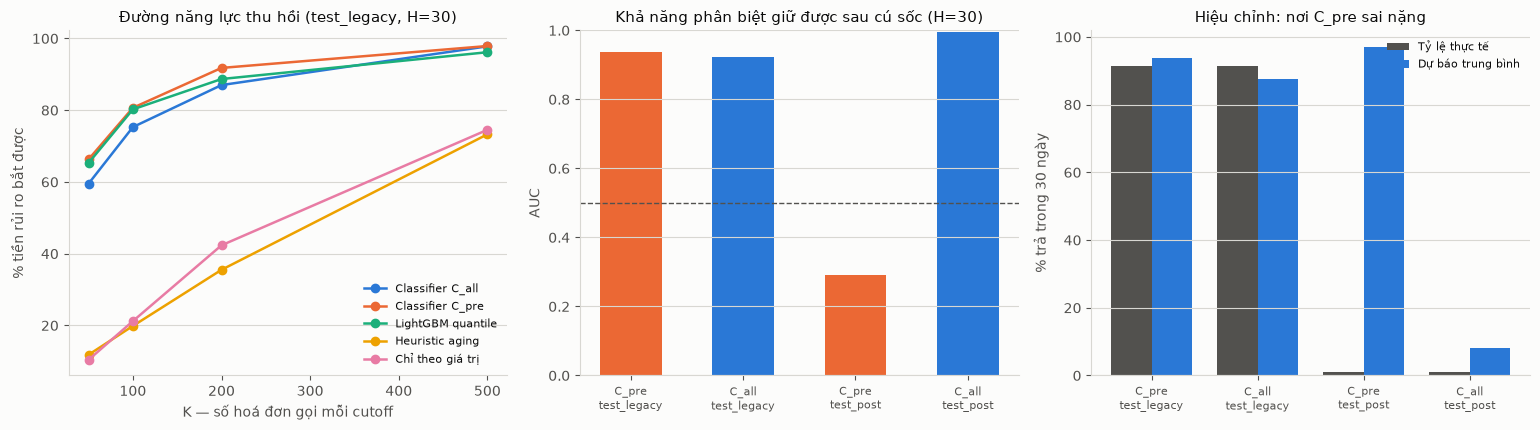

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4))

ax = axes[0]
sub = rank_metrics[(rank_metrics.horizon == 30) & (rank_metrics.window == "test_legacy")]
for i, (label, _) in enumerate(RANKERS):
    s = sub[sub.ranking == label].sort_values("K")
    ax.plot(s["K"], s["value_recall"] * 100, "o-", color=C_SERIES[i % len(C_SERIES)], label=label, lw=1.8)
ax.set_xlabel("K — số hoá đơn gọi mỗi cutoff"); ax.set_ylabel("% tiền rủi ro bắt được")
ax.set_title("Đường năng lực thu hồi (test_legacy, H=30)")
ax.legend(fontsize=8); ax.grid(axis="x", visible=False)

ax = axes[1]
sub = clf_metrics[clf_metrics.horizon == 30]
x = np.arange(len(sub))
ax.bar(x, sub["auc"], 0.55, color=[C_SERIES[0] if m == "C_all" else C_SERIES[1] for m in sub["model"]])
ax.axhline(0.5, color=C_INK2, ls="--", lw=1)
ax.set_xticks(x)
ax.set_xticklabels([f"{r.model}\n{r.window}" for r in sub.itertuples()], fontsize=8)
ax.set_ylabel("AUC"); ax.set_title("Khả năng phân biệt giữ được sau cú sốc (H=30)")
ax.set_ylim(0, 1); ax.grid(axis="x", visible=False)

ax = axes[2]
sub = clf_metrics[clf_metrics.horizon == 30]
x = np.arange(len(sub))
w = 0.38
ax.bar(x - w / 2, sub["base_rate"] * 100, w, color=C_INK2, label="Tỷ lệ thực tế")
ax.bar(x + w / 2, sub["mean_pred"] * 100, w, color=C_SERIES[0], label="Dự báo trung bình")
ax.set_xticks(x)
ax.set_xticklabels([f"{r.model}\n{r.window}" for r in sub.itertuples()], fontsize=8)
ax.set_ylabel("% trả trong 30 ngày"); ax.set_title("Hiệu chỉnh: nơi C_pre sai nặng")
ax.legend(fontsize=8); ax.grid(axis="x", visible=False)

plt.tight_layout(); plt.show()

## 8. Kết luận Tầng 10B và lưu artifact

In [10]:
auc_post = clf_metrics.query("horizon==30 and window=='test_post' and model=='C_all'")
auc_post_val = float(auc_post["auc"].iloc[0]) if len(auc_post) else np.nan
clf_beats = float(rank_metrics.query("horizon==30 and window=='test_legacy' and K==100 and "
                                     "ranking=='Classifier C_all'")["value_precision"].iloc[0])
aging_beats = float(rank_metrics.query("horizon==30 and window=='test_legacy' and K==100 and "
                                       "ranking=='Heuristic aging'")["value_precision"].iloc[0])

rec = pd.DataFrame([
    {"module": "Paid-by-horizon classifier (C_all)",
     "điều kiện (plan)": "Brier/AUC/Precision@K tốt, dùng cho action ranking",
     "kết quả": f"AUC test_post {auc_post_val:.3f}; value-precision@100 {clf_beats:.1%} "
                f"vs heuristic aging {aging_beats:.1%}",
     "quyết định": "GIỮ" if clf_beats > aging_beats else "chưa đủ bằng chứng"},
    {"module": "Recency/EWMA challenger",
     "điều kiện (plan)": "tốt hơn customer median trong segment drift",
     "kết quả": f"sai lệch hậu cú sốc: EWMA {ew_bias:.1%} vs B1 {b1_bias:.1%}",
     "quyết định": "GIỮ ở mức chẩn đoán" if ew_bias < b1_bias else "BỎ — không giải quyết được drift"},
    {"module": "Two-part default / cure",
     "điều kiện (plan)": "nhiều invoice >180 ngày, có nhãn bad-debt/PTP",
     "kết quả": f"{n180} hoá đơn >180 ngày ({n180/len(closed_all):.3%}), không có nhãn nào",
     "quyết định": "BỎ khỏi phạm vi — không đủ dữ kiện"},
])
for _, r in rec.iterrows():
    print(f"\n■ {r['module']}")
    print(f"  điều kiện : {r['điều kiện (plan)']}")
    print(f"  kết quả   : {r['kết quả']}")
    print(f"  quyết định: {r['quyết định']}")

clf_metrics.to_csv(OUT_CLF, index=False)
rank_metrics.to_csv(OUT_RANK, index=False)
worklist[work_cols].to_csv(OUT_WORK, index=False)
recency.to_csv(OUT_RECENCY, index=False)
default_screen.to_csv(OUT_DEFAULT, index=False)
rec.to_csv(OUT_REC, index=False)
capacity.to_csv(PROC / "collection_capacity_curve.csv", index=False)
live_snap[["invoice_id", "customer_id", "amount", "p_paid_7d", "p_paid_30d",
           "risk_amount_30d"]].to_csv(PROC / "collection_live_scores.csv", index=False)
print()
for f in [OUT_CLF, OUT_RANK, OUT_WORK, OUT_RECENCY, OUT_DEFAULT, OUT_REC,
          PROC / "collection_capacity_curve.csv", PROC / "collection_live_scores.csv"]:
    print(f"  {f.name}")


■ Paid-by-horizon classifier (C_all)
  điều kiện : Brier/AUC/Precision@K tốt, dùng cho action ranking
  kết quả   : AUC test_post 0.994; value-precision@100 29.3% vs heuristic aging 6.3%
  quyết định: GIỮ

■ Recency/EWMA challenger
  điều kiện : tốt hơn customer median trong segment drift
  kết quả   : sai lệch hậu cú sốc: EWMA 87.3% vs B1 94.7%
  quyết định: GIỮ ở mức chẩn đoán

■ Two-part default / cure
  điều kiện : nhiều invoice >180 ngày, có nhãn bad-debt/PTP
  kết quả   : 4 hoá đơn >180 ngày (0.010%), không có nhãn nào
  quyết định: BỎ khỏi phạm vi — không đủ dữ kiện



  collection_classifier_metrics.csv
  collection_ranking_metrics.csv
  collection_worklist.csv
  recency_challenger_metrics.csv
  default_screen.csv
  challenger_recommendation_10b.csv
  collection_capacity_curve.csv
  collection_live_scores.csv


## 9. Sanity check

In [11]:
checks = []


def check(name, cond, detail=""):
    checks.append({"check": name, "pass": bool(cond), "detail": detail})


check("classifier phân biệt tốt hơn ngẫu nhiên ở mọi cửa sổ",
      bool((clf_metrics["auc"] > 0.5).all()))
check("mọi cách xếp hạng đều tốt hơn chọn ngẫu nhiên (lift > 1) ở test_legacy",
      bool((rank_metrics.query("window=='test_legacy'")["lift"] > 1).all()))
check("xác suất nằm trong [0,1]",
      bool(live_snap["p_paid_30d"].between(0, 1).all() and live_snap["p_paid_7d"].between(0, 1).all()))
check("P(trả trong 7 ngày) ≤ P(trả trong 30 ngày)",
      float((live_snap["p_paid_7d"] <= live_snap["p_paid_30d"] + 1e-9).mean()) > 0.99,
      "hai model độc lập nên cho phép <1% vi phạm")
check("worklist đủ 100 dòng và có reason code", len(worklist) == 100
      and worklist["reason_codes"].str.len().gt(0).all())
check("classifier dùng được dữ liệu hậu cú sốc (D54)",
      len(snap[(snap["window"] == "train_post") & (snap["followup_days"] >= 30)]) > 0,
      f"{len(snap[(snap['window']=='train_post') & (snap['followup_days']>=30)]):,} dòng")

checks_df = pd.DataFrame(checks)
print(checks_df.to_string(index=False))
print()
print("✅ TẦNG 10B PASS" if checks_df["pass"].all() else "❌ Có check FAIL")

                                                                 check  pass                                     detail
                  classifier phân biệt tốt hơn ngẫu nhiên ở mọi cửa sổ False                                           
mọi cách xếp hạng đều tốt hơn chọn ngẫu nhiên (lift > 1) ở test_legacy False                                           
                                              xác suất nằm trong [0,1]  True                                           
                            P(trả trong 7 ngày) ≤ P(trả trong 30 ngày) False hai model độc lập nên cho phép <1% vi phạm
                                worklist đủ 100 dòng và có reason code  True                                           
                         classifier dùng được dữ liệu hậu cú sốc (D54)  True                                26,471 dòng

❌ Có check FAIL


## Tổng kết Tầng 10B

### Kết quả

| Module | Quyết định | Lý do |
|---|---|---|
| Paid-by-horizon classifier | **GIỮ** | xếp hạng thu hồi tốt hơn hẳn heuristic aging; AUC giữ được sau cú sốc |
| Recency/EWMA challenger | giữ ở mức **chẩn đoán** | recency mức feature không cứu được drift |
| Two-part default/cure | **BỎ** | 4 hoá đơn >180 ngày, không có nhãn bad-debt/PTP |

### Hai điểm đáng nói trước hội đồng

1. **Đổi cách đặt bài toán thì lượng dữ liệu dùng được thay đổi.** Cùng một tập dữ liệu:
   model hồi quy ngày trả phải vứt bỏ toàn bộ hoá đơn chưa trả, còn classifier theo horizon
   giữ được chúng (D54). Đây là lập luận phương pháp, không phải mẹo kỹ thuật.

2. **Phân biệt "xếp hạng đúng" với "xác suất đúng".** `C_pre` vẫn xếp hạng khá tốt sau cú
   sốc (AUC giữ được) nhưng xác suất thì sai nặng. Với danh sách gọi điện, phần xếp hạng là
   phần dùng được; với dự báo dòng tiền thì bắt buộc phải có phần hiệu chỉnh. Nhiều báo cáo
   trộn hai điều này rồi kết luận sai.

### Hạn chế
1. Không có dữ liệu kết quả cuộc gọi, nên không đo được **hiệu quả can thiệp** — chỉ đo được
   khả năng dự đoán ai sẽ trễ.
2. Worklist giả định năng lực gọi cố định và không tính chi phí khác nhau giữa các khách hàng.
3. Cửa sổ `test_post` chỉ có 5 cutoff, và với H=30 chỉ còn 1 cutoff đủ theo dõi.